# 15 — Covariance-targeting sensitivity of the FX-only model

Keep **constant world and US/Hungarian local risk prices, time-varying FX prices, corrected FX means,
zero equity alphas**, USD/EUR perspectives and **scalar11 / grouped21** covariance dynamics. Use all
**321 frozen months, 2000-01 to 2026-09**. Run notebook 13 first; notebook 14 supplies the companion
instrument/influence checks. **Run All in the existing Miniconda base kernel**; no downloads or keys.

The supplied Antell–Vaihekoski draft, equation (13), writes the covariance intercept in terms of an
unconditional innovation covariance. Here we distinguish the existing **free $CC'$ intercept** from
two explicitly estimated-and-fixed targets. Rewriting an estimated free intercept as a free long-run
covariance would leave the statistical model unchanged; fixing a sample target changes the estimator.
This two-step implementation is a documented sensitivity, not a claim to recover an undocumented
target estimator from the paper. The grouped two-shock-lag model remains our extension.

The small extension is [covariance_targeting.py](covariance_targeting.py). It maps target parameters
into the frozen pricing engine and applies the chain rule; earlier engines and outputs stay unchanged.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/13_time_varying_FX_only/fixed_2026-11-13/2000-01_2026-09/constant_world_local"
COVARIANCE_MODELS=["scalar11","grouped21"]
TARGETS=["innovations","returns"]
PD_FLOOR=1e-8
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2800
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="covariance_targeting_two_step_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys,warnings
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as covariance
import local_risk_pricing as model
import covariance_targeting as targeting
importlib.reload(base);importlib.reload(covariance);importlib.reload(model);importlib.reload(targeting)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py","local_risk_pricing.py","pricing_error_tests.py","covariance_targeting.py"]}
print("Python:",sys.executable);print("Packages:",versions)
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS) or any(m not in ["scalar11","grouped21"] for m in COVARIANCE_MODELS):raise ValueError("Use the retained covariance models.")
if not HAC_LAGS or 0 not in HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include zero and distinct nonnegative integer HAC lags.")
if not TARGETS or len(set(TARGETS))!=len(TARGETS) or any(t not in ["innovations","returns"] for t in TARGETS):raise ValueError("Choose the listed target definitions.")
if not np.isfinite(PD_FLOOR) or PD_FLOOR<=0:raise ValueError("Use a positive numerical PD floor.")
pd.set_option("display.max_columns",20);pd.set_option("display.max_rows",50);pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip");data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous working months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC bandwidth exceeds the sample.")
upstream_hashes,chain_hashes,conditioning_hashes,raw_hashes={},{},{},{}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["observations"]!=len(data) or prior["equity_alphas"]!="fixed zero" or prior["FX_means"]!="corrected pricing equations"):
    raise ValueError("Notebook 13 sample/mean restrictions differ.")
for name,digest in prior["engines"].items():
    if engine_hashes[name]!=digest:raise ValueError("An upstream engine changed.")
spec=prior["world_FX_instruments"];GLOBAL=spec["world"]
if spec["HUF_inflation"]!="change" or spec["other_inflation"]!="level" or not spec["HUF_regime"]:raise ValueError("Expected the audited change/level/regime baseline.")
ledger=prior
while "instrument_normalizers.csv" not in ledger.get("conditioning_file_sha256",{}):
    path=ROOT/ledger["upstream"]/"estimation_manifest.json";content=path.read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=ledger["upstream_file_sha256"]["estimation_manifest.json"]:raise ValueError("Provenance chain changed.")
    chain_hashes[str(path.relative_to(ROOT))]=digest;ledger=json.loads(content)
conditioning_root=ROOT/prior["conditioning_root"]
def conditioning_bytes(name):
    content=(conditioning_root/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=ledger["conditioning_file_sha256"][name]:raise ValueError(f"Conditioning checksum differs: {name}")
    if name in prior["conditioning_file_sha256"] and digest!=prior["conditioning_file_sha256"][name]:raise ValueError("Conditioning vintages differ.")
    conditioning_hashes[name]=digest;return content
normalizers=pd.read_csv(BytesIO(conditioning_bytes("instrument_normalizers.csv")),index_col=[0,1,2],float_precision="round_trip").sort_index()
prior_quality=pd.read_csv(BytesIO(conditioning_bytes("conditioning_quality_flags.csv")),index_col=[0,1])
old_summary=pd.read_csv(BytesIO(upstream_bytes("fit_summary.csv")),index_col=0,float_precision="round_trip")
archived,samples,references={}, {}, {}
for currency in ["USD","EUR"]:
    archived[currency]={}
    for label in ["H","O"]:
        z=pd.read_csv(BytesIO(conditioning_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        archived[currency][label]=z
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
    for name in COVARIANCE_MODELS:
        key=f"{currency}_{name}_FX"
        with np.load(BytesIO(upstream_bytes(f"parameters_{key}.npz")),allow_pickle=False) as a:references[(currency,name)]={k:a[k].copy() for k in a.files}
        if not np.array_equal(references[(currency,name)]["equity_alphas"],np.zeros(3)):raise ValueError("Reference alphas are not zero.")
OUT=ROOT/"output"/"15_covariance_targeting"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"two_step_targets"
OUT.mkdir(parents=True,exist_ok=True)

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


## 1. Audit fixed designs, reference fits and target matrices

No instrument is added or retimed: HUF uses the three global instruments, the lag-2 inflation-gap
change and the floating-regime dummy; the other FX price uses the three global instruments and the
lag-2 US/EA inflation-gap level, signed by perspective. Keep the archived full-sample normalization.
The persistent level conditioner and flagged carried US-inflation rate remain inherited limitations.

For the first-stage free-intercept estimate $\hat\eta$, define $\hat\epsilon_t^F=y_t-\mu_t(\hat\eta)$.
The targets, both divided by $T$ rather than $T-1$, are

$$\boxed{\hat S_{\rm innovations}=T^{-1}\sum_t\hat\epsilon_t^F\hat\epsilon_t^{F\prime},\qquad
\hat S_{\rm returns}=T^{-1}\sum_t(y_t-\bar y)(y_t-\bar y)'.}$$

The **innovation second moment is primary**; do not demean these fitted innovations. The centered
return target is a deliberately different benchmark: with a time-varying conditional mean,
$\operatorname{Var}(y_t)$ also contains $\operatorname{Var}(\mu_t)$, so it need not estimate
$E(\epsilon_t\epsilon_t')$. Each innovation target uses its own retained model's first-stage fit.

Writing $A_j=\operatorname{diag}(a_j)$ and $B=\operatorname{diag}(b)$, set

$$\boxed{\Omega=\hat S-\sum_{j=1}^{p}A_j\hat S A_j'-B\hat S B',\quad
H_t=\Omega+\sum_{j=1}^{p}A_j\epsilon_{t-j}\epsilon_{t-j}'+BH_{t-1}B'.}$$

$p=1$ for scalar11 and $p=2$ for grouped21. Initialize $H_1$ and presample shock products at
$\hat S$, matching the existing stationary initialization. In grouped dynamics, a positive target
and stationary marginal coefficients **do not alone guarantee a positive intercept**. Constrain the
smallest eigenvalue of the SD-normalized $\Omega$ above `PD_FLOOR`; record binding constraints and
withhold ordinary inference near their boundary. Never repair or shrink a target silently.

In [2]:
def make_case(currency,name,kind):
    y=samples[currency];pdesign={"W":np.ones((len(data),1)),**{a:archived[currency][a].to_numpy().copy() for a in ["H","O"]},"L":np.ones((len(data),1))}
    cols={"W":["constant"],**{a:list(archived[currency][a].columns) for a in ["H","O"]},"L":["constant"]}
    return {"id":f"{currency}_{name}_{kind}","currency":currency,"name":name,"kind":kind,"y":y,"pdesign":pdesign,"columns":cols,"scales":y.std(axis=0,ddof=1)}
def free_args(c):return c["y"],c["pdesign"],c["scales"],c["name"]
def args(c):return *free_args(c),c["target_normalized"]
first_stages,target_matrices={},{}
audit_rows,target_rows,check_rows=[],[],[]
for currency in ["USD","EUR"]:
    for label,z in archived[currency].items():
        x=z.to_numpy()
        if not np.isfinite(x).all() or np.linalg.matrix_rank(x)!=x.shape[1]:raise ValueError("Inherited design is not full rank.")
        np.testing.assert_allclose(x[:,1:].mean(axis=0),0,atol=1e-12,rtol=0)
        np.testing.assert_allclose(x[:,1:].std(axis=0,ddof=1),1,atol=1e-12,rtol=0)
        audit_rows.append({"perspective":currency,"price":label,"months":len(x),"columns":x.shape[1],"rank":np.linalg.matrix_rank(x),"condition":np.linalg.cond(x)})
    for name in COVARIANCE_MODELS:
        c=make_case(currency,name,"free");saved=references[(currency,name)];theta=saved["theta"];f=model.filter_model(theta,*free_args(c))
        for new,old in [("H","H"),("mu","mu"),("errors","residuals"),("scores","scores")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-8,rtol=1e-9)
        np.testing.assert_allclose(-f["losses"].sum(),old_summary.loc[f"{currency}_{name}_FX","loglik"],atol=1e-8,rtol=0)
        if np.max(np.abs(f["scores"].mean(axis=0)))>=1e-4:raise ValueError("First-stage reference no longer converges.")
        first_stages[(currency,name)]={"theta":theta,"filter":f}
        for kind in TARGETS:
            error=f["errors"] if kind=="innovations" else c["y"]-c["y"].mean(axis=0)
            S=error.T@error/len(data);sn=S/np.outer(c["scales"],c["scales"])
            if np.linalg.eigvalsh(sn).min()<=0:raise ValueError("Nonpositive sample target.")
            target_matrices[(currency,name,kind)]=sn
            target_rows.append({"perspective":currency,"covariance":name,"target":kind,"min_eigen_normalized":np.linalg.eigvalsh(sn).min(),"condition_normalized":np.linalg.cond(sn),
                "relative_Frobenius_from_free":np.linalg.norm((S-f["target"])/np.outer(c["scales"],c["scales"]))/np.linalg.norm(f["target"]/np.outer(c["scales"],c["scales"]))})
            probe=targeting.feasible_start(targeting.reduce_free(theta,c["pdesign"],name),c["pdesign"],name,sn,PD_FLOOR)
            sub=(c["y"][:35],{a:z[:35] for a,z in c["pdesign"].items()},c["scales"],name,sn)
            analytic=targeting.objective(probe,*sub)[1];numeric=base.numerical_gradient(lambda t:targeting.objective(t,*sub)[0],probe)
            np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
            mapped,J=targeting.free_map(probe,c["pdesign"],name,sn)
            jnum=targeting.jacobian(lambda t:targeting.free_map(t,c["pdesign"],name,sn)[0],probe,step=1e-5)
            np.testing.assert_allclose(J,jnum,atol=2e-7,rtol=2e-5)
            ft=targeting.filter_model(probe,*sub);np.testing.assert_allclose(ft["target"],S,atol=1e-10,rtol=1e-11)
            check_rows.append({"perspective":currency,"covariance":name,"target":kind,"parameters_stage2":len(probe),"score_gradient_error":np.max(np.abs(analytic-numeric)),"map_Jacobian_error":np.max(np.abs(J-jnum))})
design_audit=pd.DataFrame(audit_rows);target_audit=pd.DataFrame(target_rows);gradient_checks=pd.DataFrame(check_rows)
display(design_audit);display(target_audit);display(gradient_checks)
display(prior_quality[(prior_quality["HUF_inflation_uses_carried_US_rate"].astype(bool)|prior_quality["other_inflation_uses_carried_US_rate"].astype(bool))])

,perspective,price,months,columns,rank,condition
0,USD,H,321,6,6,1.87417
1,USD,O,321,5,5,1.9049
2,EUR,H,321,6,6,1.87531
3,EUR,O,321,5,5,1.9049


,perspective,covariance,target,min_eigen_normalized,condition_normalized,relative_Frobenius_from_free
0,USD,scalar11,innovations,0.0222541,144.825,0.114141
1,USD,scalar11,returns,0.0221487,154.732,0.170676
2,USD,grouped21,innovations,0.0221859,145.652,0.122082
3,USD,grouped21,returns,0.0221487,154.732,0.179994
4,EUR,scalar11,innovations,0.0247764,99.771,0.103908
5,EUR,scalar11,returns,0.0247552,102.049,0.138312
6,EUR,grouped21,innovations,0.0247067,100.836,0.111887
7,EUR,grouped21,returns,0.0247552,102.049,0.146563


,perspective,covariance,target,parameters_stage2,score_gradient_error,map_Jacobian_error
0,USD,scalar11,innovations,16,1.52914e-10,1.00421e-10
1,USD,scalar11,returns,16,6.78427e-11,3.84516e-11
2,USD,grouped21,innovations,23,2.05589e-10,3.88423e-09
3,USD,grouped21,returns,23,1.3632e-10,7.88525e-09
4,EUR,scalar11,innovations,16,1.22166e-10,5.61924e-11
5,EUR,scalar11,returns,16,1.35957e-10,4.53766e-11
6,EUR,grouped21,innovations,23,8.49764e-11,7.30505e-09
7,EUR,grouped21,returns,23,1.0022e-10,1.95829e-08


HUF_inflation_uses_carried_US_rate  \
perspective month                                         
USD         2025-12                                   1   
            2026-01                                   1   
EUR         2025-12                                   0   

                     other_inflation_uses_carried_US_rate  
perspective month                                          
USD         2025-12                                     1  
            2026-01                                     0  
EUR         2025-12                                     1

## 2. Re-estimate risk prices and retained dynamics

Report the four verified free-intercept references and both fixed-target definitions under each
perspective/model: **12 cases**, of which eight are new fits. Targeting removes 15 intercept
coordinates from the second-stage optimization, leaving **16 scalar / 23 grouped parameters**;
the target is still estimated, not known. Use a mapped reference start and an independent moment
start, adjusting only starting dynamics toward common coefficients if needed for a feasible intercept.

Require optimizer success, feasibility and a small bound/PD-constraint KKT gradient; show the raw
gradient as well. Keep all definitions, including fragile results. Caches include targets, exact input
arrays, starts, engines, package versions and optimizer settings. `REUSE_FITS=False` recomputes fits.

In [3]:
fits,start_rows={},[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        first=first_stages[(currency,name)]
        c=make_case(currency,name,"free");c.update(theta=first["theta"],filter=first["filter"]);fits[c["id"]]=c
        print(c["id"],"verified upstream reference",flush=True)
        for kind in TARGETS:
            c=make_case(currency,name,kind);key=c["id"];print(key,flush=True)
            c["target_normalized"]=target_matrices[(currency,name,kind)]
            starts=[targeting.reduce_free(first["theta"],c["pdesign"],name),targeting.reduce_free(model.initial_theta(*free_args(c)),c["pdesign"],name)]
            starts=[targeting.feasible_start(t,c["pdesign"],name,c["target_normalized"],PD_FLOOR) for t in starts]
            config={"version":MODEL_VERSION,"engines":engine_hashes,"case":key,"source_sha256":manifest["exports"]["dataset.csv"],"n":len(data),"first":str(data.index[0]),"last":str(data.index[-1]),
                "python":platform.python_version(),"packages":versions,"max_iter":MAX_ITER,"PD_floor":PD_FLOOR,"starts":["mapped free fit","independent moment"],"start_sha256":[hashlib.sha256(t.tobytes()).hexdigest() for t in starts],
                "upstream_sha256":upstream_hashes,"conditioning_sha256":conditioning_hashes,"target_definition":kind,"price_columns":c["columns"]}
            payload=json.dumps(config,sort_keys=True).encode()+c["y"].tobytes()+c["target_normalized"].tobytes()+b"".join(c["pdesign"][a].tobytes() for a in ["W","H","O","L"])
            fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json";record=None
            cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits=targeting.bounds(c["pdesign"],name);candidate=np.asarray(cached["theta"]) if cached else np.array([])
            if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
                value,gradient=targeting.objective(candidate,*args(c));margin,cg=targeting.constraint(candidate,c["pdesign"],name,c["target_normalized"],PD_FLOOR)
                best_start=min((r for r in cached["starts"] if r["valid"]),key=lambda r:r["mean_nll"])
                multiplier=best_start["PD_multiplier"] if margin<1e-6 else 0.
                pg=targeting.projected_gradient(candidate,gradient-multiplier*cg,limits)
                if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(pg))<1e-4 and margin>=-1e-10:record=cached;print("  verified cached fit",flush=True)
            if record is None:
                best,runs=targeting.fit_starts(args(c),starts,maxiter=MAX_ITER,pd_floor=PD_FLOOR)
                record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs};path.write_text(json.dumps(record,indent=2)+"\n")
            start_rows.extend({"case":key,**row} for row in record["starts"])
            theta=np.asarray(record["theta"]);f=targeting.filter_model(theta,*args(c));c.update(theta=theta,filter=f);fits[key]=c
            np.testing.assert_allclose(f["target"],c["target_normalized"]*np.outer(c["scales"],c["scales"]),atol=1e-10,rtol=1e-11)
            old_bounds=model.bounds(c["pdesign"],name);full=f["free_theta"]
            c["within_free_bounds"]=bool(((full>=old_bounds[:,0])&(full<=old_bounds[:,1])).all())
            if c["within_free_bounds"] and f["losses"].sum()<first["filter"]["losses"].sum()-1e-5:raise ValueError("Target fit improves the free-intercept optimum; inspect first-stage convergence.")
starting_points=pd.DataFrame(start_rows);display(starting_points)

USD_scalar11_free verified upstream reference


USD_scalar11_innovations


  verified cached fit


USD_scalar11_returns


  verified cached fit


USD_grouped21_free verified upstream reference


... (11 outputs left out)

  verified cached fit


EUR_grouped21_returns


  verified cached fit


,case,start,success,valid,mean_nll,raw_gradient,KKT_gradient,PD_margin,PD_multiplier,iterations,message
0,USD_scalar11_innovations,1,True,True,11.5929,1.13486e-07,1.13486e-07,0.00180434,0,219,Optimization terminated successfully
1,USD_scalar11_innovations,2,True,True,11.5929,1.1927e-07,1.1927e-07,0.00180434,0,259,Optimization terminated successfully
2,USD_scalar11_returns,1,True,True,11.5949,5.56252e-08,5.56252e-08,0.00176092,0,205,Optimization terminated successfully
3,USD_scalar11_returns,2,True,True,11.5949,1.58806e-07,1.58806e-07,0.00176091,0,190,Optimization terminated successfully
4,USD_grouped21_innovations,1,True,True,11.5689,8.09978e-08,8.09978e-08,0.00251179,0,292,Optimization terminated successfully
5,USD_grouped21_innovations,2,True,True,11.5689,4.80083e-10,4.80083e-10,0.00251179,0,213,Optimization terminated successfully
6,USD_grouped21_returns,1,True,True,11.572,8.04391e-08,8.04391e-08,0.00255361,0,305,Optimization terminated successfully
7,USD_grouped21_returns,2,True,True,11.572,3.24401e-09,3.24401e-09,0.00255361,0,212,Optimization terminated successfully
8,EUR_scalar11_innovations,1,True,True,11.5845,6.0297e-08,6.0297e-08,0.00213052,0,158,Optimization terminated successfully
9,EUR_scalar11_innovations,2,True,True,11.5845,1.7137e-07,1.7137e-07,0.00213052,0,171,Optimization terminated successfully


## 3. Propagate estimated-target uncertainty

For the innovation target, stack the preliminary free-model score, target moment and second-stage
score, with $s=\operatorname{vech}(S)$ in fixed SD-normalized units:

$$\psi_t(\eta,s,\beta)=\begin{bmatrix}
g_t^F(\eta)\\ s-\operatorname{vech}(u_t^F(\eta)u_t^F(\eta)')\\ g_t^{\rm target}(\beta,s)
\end{bmatrix},\qquad u_t^F=\epsilon_t^F/\text{sample SDs}.$$

Use the full block-triangular Jacobian $D=\partial\bar\psi/\partial(\eta,s,\beta)'$ and the
full-calendar Bartlett score/moment HAC meat $S_L$. The bottom block of

$$\boxed{\widehat{\operatorname{Var}}(\hat\eta,\hat s,\hat\beta)
=D^{-1}S_LD^{-1\prime}/T}$$

provides **target-adjusted** uncertainty. Cross-covariances between all stages matter. The centered
return target uses its covariance moment and second-stage score; estimating the unconditional mean
has zero first-order derivative in that centered covariance moment. Both definitions use the same
full calendar and bandwidths **0, 3, 6, 12**, without a finite-sample multiplier.

Also export **target-fixed** uncertainty, which omits target estimation. It is a comparison only;
the adjusted tests determine the main summary. Verify both differentiation steps, positive likelihood
curvature, Jacobian conditioning, coefficient bounds and intercept feasibility. Withhold unstable
ordinary tests. Test all retained FX slopes jointly and each FX block separately; Holm adjustment
covers the two component tests within each case/bandwidth/hypothesis family, not every sensitivity.

[Pedersen and Rahbek (2012)](https://pure.au.dk/ws/files/51026974/rp12_53.pdf) develop two-step
variance-targeting inference for BEKK. Our stacked equations explicitly accommodate the preliminary
GARCH-in-mean fit used here; this is not an assertion that their zero-mean model's theorem applies
unchanged. Large-sample moment and specification assumptions remain necessary. The source covariance
restriction is equation (13) in the [available Antell–Vaihekoski draft](https://www.efmaefm.org/0EFMAMEETINGS/EFMA%20ANNUAL%20MEETINGS/2005-Milan/papers/14-antell_paper.pdf).

In [4]:
fit_rows,test_rows,coefficient_rows,residual_rows,cross_rows,path_rows=[],[],[],[],[],[]
for key,c in fits.items():
    print("Uncertainty:",key,flush=True)
    theta,f=c["theta"],c["filter"];idx=model.price_indices(c["pdesign"]);first=first_stages[(c["currency"],c["name"])]
    if c["kind"]=="free":
        inf=model.inference(theta,free_args(c),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL)
        inf["estimates"]={("joint_QML",h):v for h,v in inf["estimates"].items()};inf["stack_Jacobian"]=inf["Hessian"];inf["stack_scores"]=f["scores"]
        inf["Jacobian_condition"]=inf["Hessian_condition"];inf["Jacobian_step_difference"]=inf["Hessian_step_difference"]
        inf["PD_margin"]=np.linalg.eigvalsh(f["intercept"]/np.outer(c["scales"],c["scales"])).min()-PD_FLOOR
        primary="joint_QML";raw_gradient=np.max(np.abs(f["scores"].mean(axis=0)))
        for (_,h),v in inf["estimates"].items():
            if v["ready"]:np.testing.assert_allclose(v["covariance"],references[(c["currency"],c["name"])][f"covariance_HAC{h}"],atol=2e-6,rtol=2e-6)
    else:
        inf=targeting.inference(theta,args(c),f,c["kind"],first["theta"],first["filter"],hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL,pd_floor=PD_FLOOR)
        primary="target_adjusted";raw_gradient=np.max(np.abs(targeting.objective(theta,*args(c))[1]))
    c["inference"],c["primary"]=inf,primary
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if c["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows());cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    reference=first["filter"]
    fit_rows.append({"case":key,"perspective":c["currency"],"covariance":c["name"],"target":c["kind"],"months":len(data),"optimization_parameters":len(theta),"target_moments":15 if c["kind"]!="free" else 0,
        "stack_dimension":len(inf["stack_Jacobian"]),"loglik":-f["losses"].sum(),"delta_loglik_from_free":reference["losses"].sum()-f["losses"].sum(),"raw_gradient":raw_gradient,
        "PD_margin":inf["PD_margin"],"near_bound":inf["near_bound"],"Jacobian_condition":inf["Jacobian_condition"],"Jacobian_step_difference":inf["Jacobian_step_difference"],
        "primary_regular_all_lags":all(inf["estimates"][(primary,h)]["ready"] for h in HAC_LAGS),"within_free_bounds":c.get("within_free_bounds",True),
        "mean_flags":int((marginal["LB_z_p"]<.05).sum()),"variance_flags":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),"cross_flags":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum())})
    restrictions={"FX prices constant":np.r_[idx["H"][1:],idx["O"][1:]],"FX prices zero":np.r_[idx["H"],idx["O"]],"HUF price constant":idx["H"][1:],"Other FX price constant":idx["O"][1:],
        "HUF price zero":idx["H"],"Other FX price zero":idx["O"],"World price zero":idx["W"],"Hungarian local price zero":idx["L"],"Local prices jointly zero":np.r_[1,idx["L"]]}
    for (method,h),estimate in inf["estimates"].items():
        V=estimate["covariance"];rows={label:base.wald(theta,V,positions) for label,positions in restrictions.items()};adjusted={}
        for pair in [("HUF price constant","Other FX price constant"),("HUF price zero","Other FX price zero")]:
            pp=[rows[label]["robust_p_value"] for label in pair]
            correction=multipletests(pp,method="holm")[1] if np.isfinite(pp).all() else [np.nan,np.nan]
            adjusted.update(dict(zip(pair,correction)))
        for label,row in rows.items():
            ready=estimate["ready"] and np.isfinite(row["robust_p_value"])
            reason=estimate["reason"] if ready or not estimate["ready"] else "restriction covariance singular/ill-conditioned"
            test_rows.append({"case":key,"method":method,"HAC_lags":h,"test":label,**row,"component_holm_p":adjusted.get(label,np.nan),"inference_ready":ready,"reason":reason,"SE_step_difference":estimate["price_SE_step_difference"]})
        for label,positions in idx.items():
            for j,instrument in zip(positions,c["columns"][label]):coefficient_rows.append({"case":key,"method":method,"HAC_lags":h,"price":label,"instrument":instrument,"estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
        coefficient_rows.append({"case":key,"method":method,"HAC_lags":h,"price":"US_local","instrument":"constant","estimate":base.PRICE_SCALE*theta[1],"robust_se":base.PRICE_SCALE*np.sqrt(V[1,1])})
    for j,label in enumerate(["H","O"]):
        a0,a1=reference["fx_prices"][:,j],f["fx_prices"][:,j];d=a1-a0
        path_rows.append({"case":key,"price":label,"mean_price":a1.mean(),"sd_price":a1.std(ddof=1),"correlation_with_free":np.corrcoef(a0,a1)[0,1],"mean_difference_from_free":d.mean(),"RMSE_over_free_SD":np.sqrt(np.mean(d**2))/a0.std(ddof=1)})
    p=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],"other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":f["local_prices"]*f["H"][:,2,2]},index=data.index)
    np.testing.assert_allclose(p.sum(axis=1),f["mu"][:,2],atol=1e-11,rtol=1e-11);c["premia"]=p.assign(total=f["mu"][:,2])
fit_summary=pd.DataFrame(fit_rows).set_index("case");tests=pd.DataFrame(test_rows).set_index(["case","method","HAC_lags","test"])
coefficients=pd.DataFrame(coefficient_rows).set_index(["case","method","HAC_lags","price","instrument"]);path_comparison=pd.DataFrame(path_rows).set_index(["case","price"])
residuals=pd.DataFrame(residual_rows).set_index(["case","series"]);cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
summary_rows=[]
for key,c in fits.items():
    r=fit_summary.loc[key];p=tests.xs((key,c["primary"],"FX prices constant"),level=("case","method","test"))["robust_p_value"].reindex(HAC_LAGS)
    summary_rows.append({"case":key,"perspective":c["currency"],"covariance":c["name"],"target":c["kind"],"method":c["primary"],"months":len(data),"optimization_parameters":len(c["theta"]),
        "regular_all_lags":r["primary_regular_all_lags"],"joint_test_complete":p.notna().all(),"FX_constancy_p_HAC0":p.loc[0],"FX_constancy_p_min":p.min(),"FX_constancy_p_max":p.max(),
        "FX_zero_p_HAC0":tests.loc[(key,c["primary"],0,"FX prices zero"),"robust_p_value"],"HUF_constancy_holm_p_HAC0":tests.loc[(key,c["primary"],0,"HUF price constant"),"component_holm_p"],
        "other_constancy_holm_p_HAC0":tests.loc[(key,c["primary"],0,"Other FX price constant"),"component_holm_p"],"variance_flags":r["variance_flags"],"cross_flags":r["cross_flags"]})
summary=pd.DataFrame(summary_rows).set_index("case")
uncertainty_comparison=tests.xs("FX prices constant",level="test")["robust_p_value"].unstack("method")
display(summary);display(fit_summary);display(uncertainty_comparison)

Uncertainty: USD_scalar11_free


Uncertainty: USD_scalar11_innovations


Uncertainty: USD_scalar11_returns


Uncertainty: USD_grouped21_free


Uncertainty: USD_grouped21_innovations


Uncertainty: USD_grouped21_returns


... (5 outputs left out)

Uncertainty: EUR_grouped21_returns


,perspective,covariance,target,method,months,optimization_parameters,regular_all_lags,joint_test_complete,FX_constancy_p_HAC0,FX_constancy_p_min,FX_constancy_p_max,FX_zero_p_HAC0,HUF_constancy_holm_p_HAC0,other_constancy_holm_p_HAC0,variance_flags,cross_flags
case,,,,,,,,,,,,,,,,
USD_scalar11_free,USD,scalar11,free,joint_QML,321,31,True,True,0.000316678,2.15812e-09,0.000316678,0.00078527,0.0781585,0.0596175,4,0
USD_scalar11_innovations,USD,scalar11,innovations,target_adjusted,321,16,True,True,9.19704e-05,1.11333e-08,9.19704e-05,0.000263563,0.0589655,0.0415691,4,0
USD_scalar11_returns,USD,scalar11,returns,target_adjusted,321,16,True,True,2.05962e-06,5.14316e-11,2.05962e-06,6.3867e-06,0.0268288,0.0240508,4,0
USD_grouped21_free,USD,grouped21,free,joint_QML,321,38,True,True,0.000280131,8.03808e-09,0.000280131,0.00065075,0.0673183,0.0673183,1,0
USD_grouped21_innovations,USD,grouped21,innovations,target_adjusted,321,23,True,True,0.000158596,1.78466e-08,0.000158596,0.000405235,0.0495785,0.0495785,3,0
USD_grouped21_returns,USD,grouped21,returns,target_adjusted,321,23,True,True,2.77963e-06,3.47346e-11,2.77963e-06,7.44038e-06,0.0172089,0.0208722,3,0
EUR_scalar11_free,EUR,scalar11,free,joint_QML,321,31,True,True,7.69171e-06,1.54718e-10,7.69171e-06,2.2157e-06,0.00765807,0.00765807,2,0
EUR_scalar11_innovations,EUR,scalar11,innovations,target_adjusted,321,16,True,True,3.54052e-06,1.37232e-09,3.54052e-06,1.49485e-06,0.00488828,0.00453594,3,0
EUR_scalar11_returns,EUR,scalar11,returns,target_adjusted,321,16,True,True,2.51699e-08,7.41694e-12,2.51699e-08,7.11434e-09,0.00108339,0.00108339,3,0


,perspective,covariance,target,months,optimization_parameters,target_moments,stack_dimension,loglik,delta_loglik_from_free,raw_gradient,PD_margin,near_bound,Jacobian_condition,Jacobian_step_difference,primary_regular_all_lags,within_free_bounds,mean_flags,variance_flags,cross_flags,variance_flags_holm
case,,,,,,,,,,,,,,,,,,,,
USD_scalar11_free,USD,scalar11,free,321,31,0,31,-3719.45,0,3.71562e-07,0.00200591,False,1.89887e+06,8.15328e-07,True,True,0,4,0,2
USD_scalar11_innovations,USD,scalar11,innovations,321,16,15,62,-3721.33,-1.88315,1.12902e-07,0.00180434,False,1.89889e+06,1.40162e-06,True,True,0,4,0,4
USD_scalar11_returns,USD,scalar11,returns,321,16,15,31,-3721.96,-2.51402,5.56252e-08,0.00176092,False,28950.6,0.000138722,True,True,0,4,0,4
USD_grouped21_free,USD,grouped21,free,321,38,0,38,-3711.63,0,8.20134e-08,0.00276809,False,1.22437e+06,5.81614e-07,True,True,0,1,0,0
USD_grouped21_innovations,USD,grouped21,innovations,321,23,15,76,-3713.61,-1.98042,4.80083e-10,0.00251179,False,1.22445e+06,1.15926e-06,True,True,0,3,0,0
USD_grouped21_returns,USD,grouped21,returns,321,23,15,38,-3714.61,-2.97323,3.24401e-09,0.00255361,False,37032.4,3.93462e-05,True,True,0,3,0,0
EUR_scalar11_free,EUR,scalar11,free,321,31,0,31,-3716.61,0,1.9656e-06,0.00239518,False,691472,7.88108e-07,True,True,0,2,0,1
EUR_scalar11_innovations,EUR,scalar11,innovations,321,16,15,62,-3718.63,-2.02003,6.0297e-08,0.00213052,False,696714,1.12282e-06,True,True,0,3,0,2
EUR_scalar11_returns,EUR,scalar11,returns,321,16,15,31,-3719.35,-2.73681,3.78084e-08,0.00207266,False,10789,0.000105556,True,True,0,3,0,1


method                               joint_QML  target_adjusted  target_fixed
case                      HAC_lags                                           
EUR_grouped21_free        0        2.74192e-05              NaN           NaN
                          3        1.50654e-05              NaN           NaN
                          6        7.45429e-06              NaN           NaN
                          12       3.61228e-08              NaN           NaN
EUR_grouped21_innovations 0                NaN      1.71245e-05   4.66111e-06
                          3                NaN      7.21177e-06   4.76995e-06
                          6                NaN      2.93189e-06    3.7832e-06
                          12               NaN       1.5723e-08   1.71401e-06
EUR_grouped21_returns     0                NaN      8.63767e-08   2.09088e-06
                          3                NaN      3.74921e-08   2.07972e-06
                          6                NaN      1.63396e-08   1.77205e-06
                          12               NaN      2.01495e-11   8.83565e-07
EUR_scalar11_free         0        7.69171e-06              NaN           NaN
                          3        3.73384e-06              NaN           NaN
                          6         2.4979e-07              NaN           NaN
                          12       1.54718e-10              NaN           NaN
EUR_scalar11_innovations  0                NaN      3.54052e-06   1.49837e-06
                          3                NaN      1.96903e-06   2.53222e-06
                          6                NaN      1.99558e-07   6.89564e-07
                          12               NaN      1.37232e-09   3.38396e-07
EUR_scalar11_returns      0                NaN      2.51699e-08    5.6486e-07
                          3                NaN      1.60354e-08   8.78204e-07
                          6                NaN      1.54464e-09   2.18953e-07
                          12               NaN      7.41694e-12   1.11148e-07
USD_grouped21_free        0        0.000280131              NaN           NaN
                          3        1.91991e-05              NaN           NaN
                          6        3.76249e-06              NaN           NaN
                          12       8.03808e-09              NaN           NaN
USD_grouped21_innovations 0                NaN      0.000158596   3.86746e-05
                          3                NaN      1.13559e-05   5.52451e-06
                          6                NaN      2.39767e-06   1.52278e-06
                          12               NaN      1.78466e-08   2.72795e-07
USD_grouped21_returns     0                NaN      2.77963e-06   2.08053e-05
                          3                NaN       1.5103e-07   2.84012e-06
                          6                NaN      2.17337e-08   7.59223e-07
                          12               NaN      3.47346e-11   1.30279e-07
USD_scalar11_free         0        0.000316678              NaN           NaN
                          3        2.20045e-05              NaN           NaN
                          6        1.60297e-06              NaN           NaN
                          12       2.15812e-09              NaN           NaN
USD_scalar11_innovations  0                NaN      9.19704e-05   2.66786e-05
                          3                NaN      7.18807e-06   4.06454e-06
                          6                NaN      9.74177e-07   7.36131e-07
                          12               NaN      1.11333e-08   2.97436e-07
USD_scalar11_returns      0                NaN      2.05962e-06   1.19172e-05
                          3                NaN      8.76798e-08   1.44603e-06
                          6                NaN      8.62993e-09   2.36159e-07
                          12               NaN      5.14316e-11   1.07879e-07

## 4. Inspect test and fitted-price sensitivity

For each case, dots show the **primary** HAC(0) joint-constancy p-value and lines its range across the
four bandwidths; this range is not a confidence interval. For targets, primary means **target-adjusted**.
The second figure compares full-calendar FX-price paths with their matched free-intercept reference.
RMSE divided by the reference price's SD captures both level and shape changes; it is not a forecast
score. Full-path residual checks remain relevant even when a risk-price test rejects.

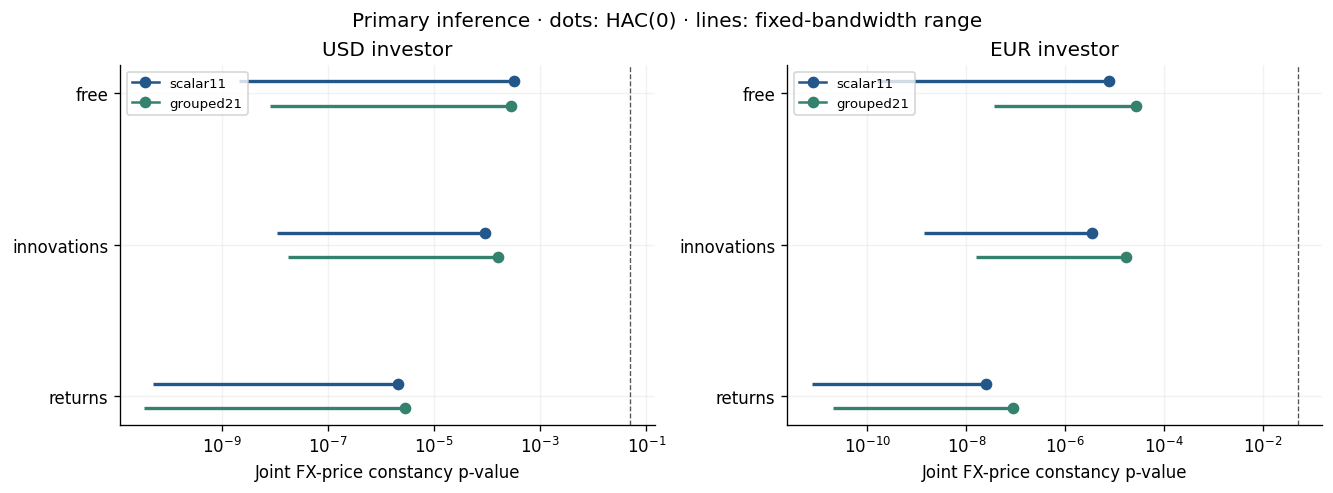

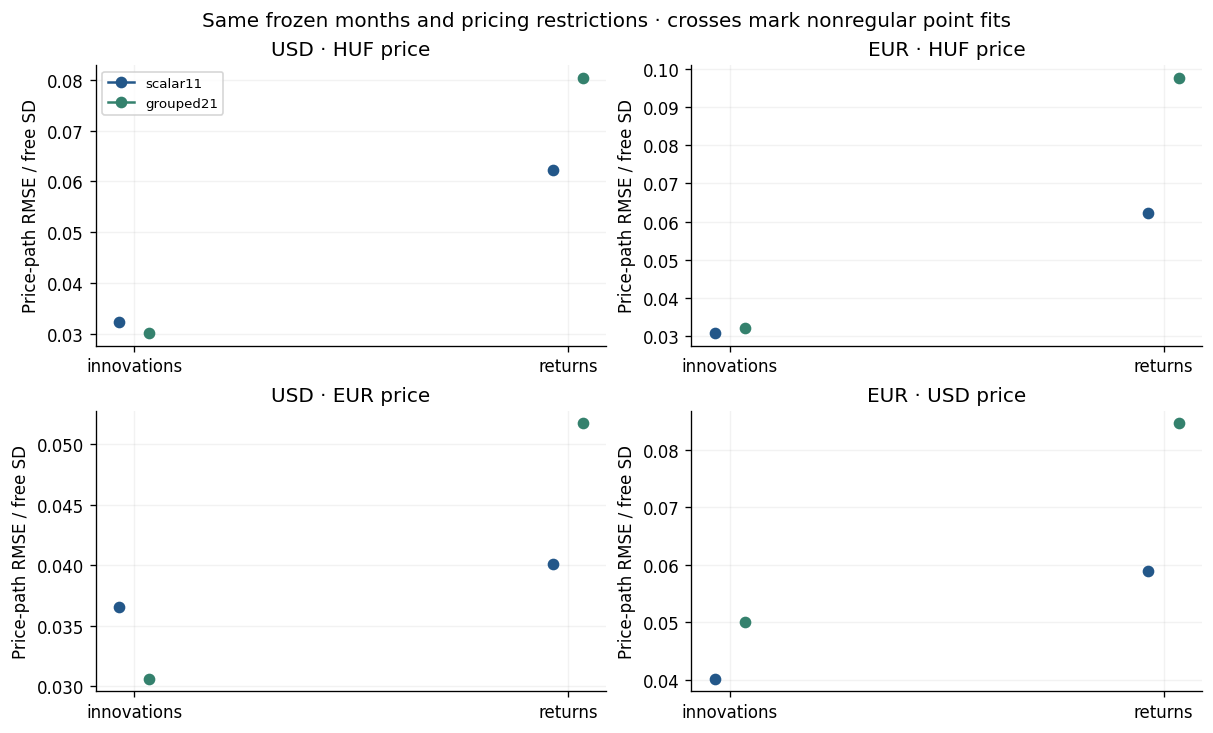

In [5]:
colors={"scalar11":"#235789","grouped21":"#34816d"};kinds=["free",*TARGETS]
fig,axes=plt.subplots(1,2,figsize=(11,4),layout="constrained",squeeze=False)
for ax,currency in zip(axes[0],["USD","EUR"]):
    for m,name in enumerate(COVARIANCE_MODELS):
        offset=.16*(m-(len(COVARIANCE_MODELS)-1)/2)
        for j,kind in enumerate(kinds):
            key=f"{currency}_{name}_{kind}";r=summary.loc[key]
            if r["regular_all_lags"] and r["joint_test_complete"]:
                ax.hlines(j+offset,r["FX_constancy_p_min"],r["FX_constancy_p_max"],color=colors[name],lw=2)
                ax.plot(r["FX_constancy_p_HAC0"],j+offset,marker="o",color=colors[name],label=name if j==0 else None)
            else:ax.text(.98,j+offset,"withheld",transform=ax.get_yaxis_transform(),ha="right",color=colors[name],fontsize=8)
    ax.axvline(.05,color="#555555",lw=.8,ls="--");ax.set_xscale("log");ax.invert_yaxis()
    ax.set(title=f"{currency} investor",xlabel="Joint FX-price constancy p-value",yticks=range(len(kinds)),yticklabels=kinds);ax.legend(fontsize=8)
fig.suptitle("Primary inference · dots: HAC(0) · lines: fixed-bandwidth range")
plt.savefig(OUT/"01_targeting_tests.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
fig,axes=plt.subplots(2,2,figsize=(10,6),layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,label in enumerate(["H","O"]):
        ax=axes[row,col]
        for m,name in enumerate(COVARIANCE_MODELS):
            for j,kind in enumerate(TARGETS):
                key=f"{currency}_{name}_{kind}";ready=summary.loc[key,"regular_all_lags"]
                ax.plot(j+.07*(m-(len(COVARIANCE_MODELS)-1)/2),path_comparison.loc[(key,label),"RMSE_over_free_SD"],marker="o" if ready else "x",color=colors[name],label=name if j==0 else None)
        other="EUR" if currency=="USD" else "USD"
        ax.set(title=f"{currency} · {('HUF' if label=='H' else other)} price",ylabel="Price-path RMSE / free SD",xticks=range(len(TARGETS)),xticklabels=TARGETS)
axes[0,0].legend(fontsize=8)
fig.suptitle("Same frozen months and pricing restrictions · crosses mark nonregular point fits")
plt.savefig(OUT/"02_targeting_price_paths.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 5. Save all cases and the final comparison

Export the target matrices, intercepts, full covariance/mean paths, first-stage and targeted parameters,
designs, risk-price paths and Hungarian premium decompositions, stacked estimating functions/Jacobians,
both uncertainty calculations and all bandwidths. Target-fixed tests are labelled comparisons only.

Compare likelihoods descriptively on the same 321 months. **Do not apply an ordinary likelihood-ratio
test or an AIC/BIC penalty based only on the reduced second-stage parameter count:** the targets are
estimated from these observations and the target fits are two-step estimators. This notebook does not
replace notebook 13's jointly estimated-model catalog. It assesses how its FX-price conclusions and
paths respond to the covariance restriction. Results remain conditional on the public proxies,
instruments, covariance dynamics and large-sample approximations already documented.

In [6]:
tables={"summary.csv":summary,"fit_summary.csv":fit_summary,"restriction_tests.csv":tests,"price_coefficients.csv":coefficients,"uncertainty_comparison.csv":uncertainty_comparison,
    "design_audit.csv":design_audit,"target_audit.csv":target_audit,"gradient_checks.csv":gradient_checks,"starting_points.csv":starting_points,"path_comparison.csv":path_comparison,
    "residual_diagnostics.csv":residuals,"cross_covariance_diagnostics.csv":cross_diagnostics}
for name,table in tables.items():table.to_csv(OUT/name)
for key,c in fits.items():
    f,inf=c["filter"],c["inference"];first=first_stages[(c["currency"],c["name"])]
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=c["theta"],free_theta=f.get("free_theta",c["theta"]),first_stage_theta=first["theta"],
        target=f["target"],intercept=f["intercept"],H=f["H"],mu=f["mu"],equity_alphas=np.zeros(3),residuals=f["errors"],scores=f["scores"],Hessian=inf["Hessian"],
        stacked_Jacobian=inf["stack_Jacobian"],stacked_scores=inf["stack_scores"],**{f"covariance_{method}_HAC{h}":v["covariance"] for (method,h),v in inf["estimates"].items()})
    c["premia"].to_csv(OUT/f"Hungary_decomposition_{key}.csv")
    pd.DataFrame({"world":f["world_prices"],"HUF_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"HU_local":f["local_prices"],"US_local":f["prices"][1]},index=data.index).to_csv(OUT/f"price_paths_{key}.csv")
    pd.DataFrame(f["target"],index=["World","US","HU","HUF","OtherFX"],columns=["World","US","HU","HUF","OtherFX"]).to_csv(OUT/f"target_{key}.csv")
    for label,z in c["pdesign"].items():pd.DataFrame(z,index=data.index,columns=c["columns"][label]).to_csv(OUT/f"design_{key}_{label}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
    "covariance_models":COVARIANCE_MODELS,"targets":TARGETS,"target_divisor":"T","primary_target":"preliminary free-model innovation second moment, uncentered", "benchmark_target":"centered observed-return covariance",
    "equity_alphas":"fixed zero","FX_means":"corrected pricing equations","world_local_prices":"constant","FX_prices":"time varying, archived notebook 13 instruments",
    "initialization":"target covariance for first H and presample shock products","PD_floor_normalized_intercept":PD_FLOOR,"HAC_lags":HAC_LAGS,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,
    "primary_inference":"stacked first-stage score / target moment / targeted score sandwich; centered Bartlett HAC, full T, no finite-sample multiplier",
    "upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,"provenance_chain_sha256":chain_hashes,"conditioning_root":str(conditioning_root.relative_to(ROOT)),"conditioning_file_sha256":conditioning_hashes,
    "engines":engine_hashes,"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
display(Markdown("**Final joint FX-price constancy p-values — primary uncertainty, HAC(0)**"))
display(summary.pivot(index="target",columns=["perspective","covariance"],values="FX_constancy_p_HAC0").reindex(["free",*TARGETS]))
display(Markdown("**Joint constancy across bandwidths and component constancy at HAC(0)**"))
display(summary[["FX_constancy_p_min","FX_constancy_p_max","HUF_constancy_holm_p_HAC0","other_constancy_holm_p_HAC0","variance_flags","cross_flags"]])
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        q=summary[(summary["perspective"]==currency)&(summary["covariance"]==name)];complete=q["regular_all_lags"]&q["joint_test_complete"]
        stable=complete&q["FX_constancy_p_max"].lt(.05)
        display(Markdown(f"**{currency} · {name}:** joint constancy rejected at 5% for every fixed bandwidth in **{int(stable.sum())}/{len(q)}** cases including the free reference; complete regular cases **{int(complete.sum())}/{len(q)}**."))
fragile=summary[(~summary["regular_all_lags"])|(~summary["joint_test_complete"])|summary["FX_constancy_p_max"].ge(.05)]
if len(fragile):
    display(Markdown("**Cases requiring qualification**"));display(fragile)
    display(tests[~tests["inference_ready"]][["reason","SE_step_difference"]])
display(Markdown(f"Saved under `{OUT.relative_to(ROOT)}`. Frozen data, earlier estimates and the base kernel were retained. Target adjustment, numerical eligibility and full-path diagnostics determine how strongly the price tests can be interpreted."))

**Final joint FX-price constancy p-values — primary uncertainty, HAC(0)**

perspective         USD                     EUR            
covariance     scalar11   grouped21    scalar11   grouped21
target                                                     
free        0.000316678 0.000280131 7.69171e-06 2.74192e-05
innovations 9.19704e-05 0.000158596 3.54052e-06 1.71245e-05
returns     2.05962e-06 2.77963e-06 2.51699e-08 8.63767e-08

**Joint constancy across bandwidths and component constancy at HAC(0)**

,FX_constancy_p_min,FX_constancy_p_max,HUF_constancy_holm_p_HAC0,other_constancy_holm_p_HAC0,variance_flags,cross_flags
case,,,,,,
USD_scalar11_free,2.15812e-09,0.000316678,0.0781585,0.0596175,4,0
USD_scalar11_innovations,1.11333e-08,9.19704e-05,0.0589655,0.0415691,4,0
USD_scalar11_returns,5.14316e-11,2.05962e-06,0.0268288,0.0240508,4,0
USD_grouped21_free,8.03808e-09,0.000280131,0.0673183,0.0673183,1,0
USD_grouped21_innovations,1.78466e-08,0.000158596,0.0495785,0.0495785,3,0
USD_grouped21_returns,3.47346e-11,2.77963e-06,0.0172089,0.0208722,3,0
EUR_scalar11_free,1.54718e-10,7.69171e-06,0.00765807,0.00765807,2,0
EUR_scalar11_innovations,1.37232e-09,3.54052e-06,0.00488828,0.00453594,3,0
EUR_scalar11_returns,7.41694e-12,2.51699e-08,0.00108339,0.00108339,3,0


**USD · scalar11:** joint constancy rejected at 5% for every fixed bandwidth in **3/3** cases including the free reference; complete regular cases **3/3**.

**USD · grouped21:** joint constancy rejected at 5% for every fixed bandwidth in **3/3** cases including the free reference; complete regular cases **3/3**.

**EUR · scalar11:** joint constancy rejected at 5% for every fixed bandwidth in **3/3** cases including the free reference; complete regular cases **3/3**.

**EUR · grouped21:** joint constancy rejected at 5% for every fixed bandwidth in **3/3** cases including the free reference; complete regular cases **3/3**.

Saved under `output/15_covariance_targeting/fixed_2026-11-13/2000-01_2026-09/two_step_targets`. Frozen data, earlier estimates and the base kernel were retained. Target adjustment, numerical eligibility and full-path diagnostics determine how strongly the price tests can be interpreted.

## Reading the recorded frozen run

These findings describe the default target definitions and numerical settings above.

- **Joint FX time variation survives targeting.** All **12 cases** are numerically regular and reject joint FX-price constancy at 5% at every fixed HAC bandwidth. With the primary innovation target and target-adjusted uncertainty, HAC(0) p-values are **0.0000920 / 0.000159 for USD** and **0.00000354 / 0.0000171 for EUR** (scalar / grouped).
- **Fitted price paths move modestly:** under the innovation target, RMSE from the matched free-intercept path is approximately **3–5% of that path's SD**. The centered-return benchmark moves them more, but it targets a different population quantity when conditional means vary. Do not choose it because its p-values happen to be smaller.
- **The HUF-specific claim remains more delicate.** Under the primary target, USD two-block Holm-adjusted HUF constancy p-values at HAC(0) are **0.0590 / 0.0496**. Strong joint FX evidence does not establish each currency's time variation equally strongly, and it does not overturn notebook 14's timing/form sensitivities.
- **Target adjustment matters:** treating the estimated target as known produces different standard errors and tests. Its effect can go in either direction because the stages use the same observations. Use the adjusted results in the main comparison.

Covariance targeting does not remove the remaining residual variance flags or establish all large-sample assumptions. The next work is the final research synthesis and reproducibility/release package, keeping the free-intercept results, targeted sensitivities and earlier qualifications together.